# Giai đoạn 1: Tìm hiểu dữ liệu (Data Understanding & EDA)
**Dự án:** Phân tích dữ liệu thương mại điện tử Olist (Brazil, 2016–2018)

**Mục tiêu:**
- Hiểu cấu trúc 9 bảng dữ liệu gốc và quan hệ giữa chúng
- Đánh giá chất lượng dữ liệu: kiểu dữ liệu, giá trị thiếu, trùng lặp, ngoại lai
- Đưa ra các quyết định làm sạch cho Giai đoạn 2

## 1. Đọc dữ liệu & Tổng quan 9 bảng
Bộ dữ liệu Olist gồm 9 bảng liên kết qua các khoá: `order_id`, `customer_id`, `product_id`, `seller_id`, `zip_code_prefix`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RAW_DIR = "../data/raw/"

file_names = {
    'orders': 'olist_orders_dataset.csv',
    'items': 'olist_order_items_dataset.csv',
    'payments': 'olist_order_payments_dataset.csv',
    'reviews': 'olist_order_reviews_dataset.csv',
    'products': 'olist_products_dataset.csv',
    'customers': 'olist_customers_dataset.csv',
    'sellers': 'olist_sellers_dataset.csv',
    'geo': 'olist_geolocation_dataset.csv',
    'category': 'product_category_name_translation.csv'
}
dfs = {name: pd.read_csv(os.path.join(RAW_DIR, f)) for name, f in file_names.items()}

overview = pd.DataFrame({
    'rows': {n: d.shape[0] for n, d in dfs.items()},
    'cols': {n: d.shape[1] for n, d in dfs.items()},
    'duplicate_rows': {n: int(d.duplicated().sum()) for n, d in dfs.items()},
    'missing_cells': {n: int(d.isna().sum().sum()) for n, d in dfs.items()},
})
overview

,rows,cols,duplicate_rows,missing_cells
orders,99441,8,0,4908
items,112650,7,0,0
payments,103886,5,0,0
reviews,99224,7,0,145903
products,32951,9,0,2448
customers,99441,5,0,0
sellers,3095,4,0,0
geo,1000163,5,261831,0
category,71,2,0,0


## 2. Giá trị thiếu & kiểu dữ liệu
Kiểm tra cột nào thiếu dữ liệu và các cột thời gian đang ở dạng `object` (chuỗi) cần ép kiểu.

In [2]:
missing = []
for name, d in dfs.items():
    na = d.isna().sum()
    for col, cnt in na[na > 0].items():
        missing.append({'table': name, 'column': col, 'missing': cnt, 'pct': round(cnt / len(d) * 100, 2)})
missing_df = pd.DataFrame(missing).sort_values('pct', ascending=False).reset_index(drop=True)

print("Kiểu dữ liệu bảng orders:")
print(dfs['orders'].dtypes)
missing_df

Kiểu dữ liệu bảng orders:
order_id                         object
customer_id                      object
order_status                     object
order_purchase_timestamp         object
order_approved_at                object
order_delivered_carrier_date     object
order_delivered_customer_date    object
order_estimated_delivery_date    object
dtype: object


,table,column,missing,pct
0,reviews,review_comment_title,87656,88.34
1,reviews,review_comment_message,58247,58.70
2,orders,order_delivered_customer_date,2965,2.98
3,products,product_category_name,610,1.85
4,products,product_name_lenght,610,1.85
5,products,product_description_lenght,610,1.85
6,products,product_photos_qty,610,1.85
7,orders,order_delivered_carrier_date,1783,1.79
8,orders,order_approved_at,160,0.16
9,products,product_weight_g,2,0.01


## 3. Trạng thái đơn hàng
Phần lớn phân tích doanh thu/giao hàng chỉ có ý nghĩa với đơn đã giao (`delivered`).

order_status
delivered      97.02 %
shipped         1.11 %
canceled        0.63 %
unavailable     0.61 %
invoiced        0.32 %
processing       0.3 %
created         0.01 %
approved         0.0 %
Name: count, dtype: object


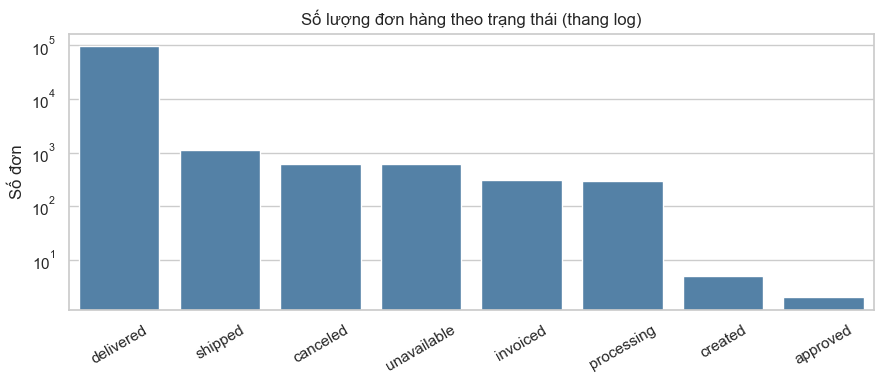

In [3]:
status = dfs['orders']['order_status'].value_counts()
print((status / status.sum() * 100).round(2).astype(str) + ' %')

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(x=status.index, y=status.values, ax=ax, color='steelblue')
ax.set_yscale('log')
ax.set_title('Số lượng đơn hàng theo trạng thái (thang log)')
ax.set_xlabel('')
ax.set_ylabel('Số đơn')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 4. Phân phối giá trị & ngoại lai
Giá sản phẩm, phí vận chuyển và giá trị thanh toán thường lệch phải mạnh.

,count,mean,std,min,25%,50%,75%,max
price,112650.0,120.653739,183.633928,0.85,39.90,74.99,134.90,6735.00
freight_value,112650.0,19.990320,15.806405,0.00,13.08,16.26,21.15,409.68


,count,mean,std,min,25%,50%,75%,max
payment_value,103886.0,154.100380,217.494064,0.0,56.79,100.0,171.8375,13664.08
payment_installments,103886.0,2.853349,2.687051,0.0,1.00,1.0,4.0000,24.00


Ngưỡng IQR trên của price = 277.40 BRL -> 8427 dòng (7.48%) là ngoại lai


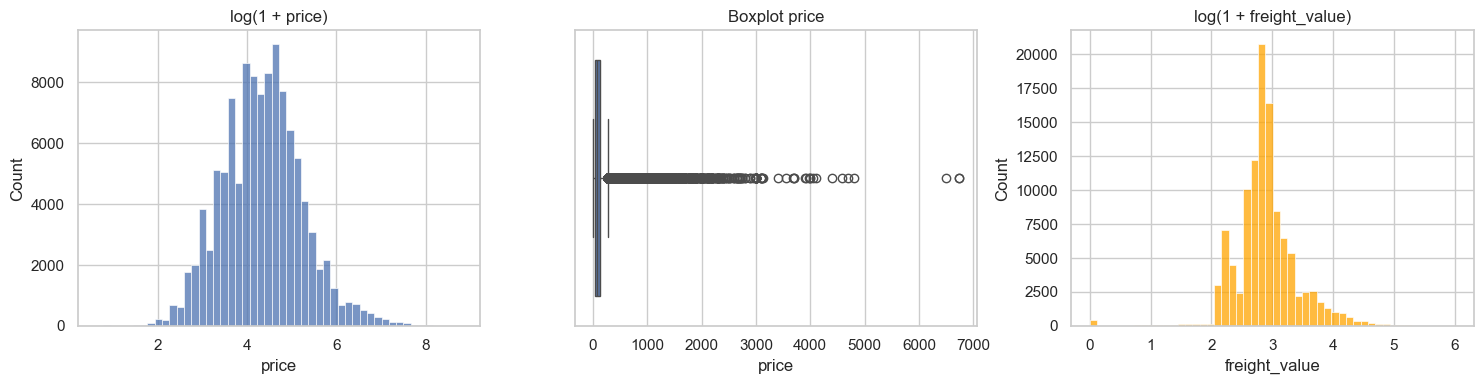

In [4]:
num = pd.DataFrame({
    'price': dfs['items']['price'],
    'freight_value': dfs['items']['freight_value'],
})
display(num.describe().T)
display(dfs['payments'][['payment_value', 'payment_installments']].describe().T)

Q1, Q3 = dfs['items']['price'].quantile([0.25, 0.75])
upper = Q3 + 1.5 * (Q3 - Q1)
n_out = (dfs['items']['price'] > upper).sum()
print(f"Ngưỡng IQR trên của price = {upper:.2f} BRL -> {n_out} dòng ({n_out / len(dfs['items']) * 100:.2f}%) là ngoại lai")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(np.log1p(dfs['items']['price']), bins=50, ax=axes[0])
axes[0].set_title('log(1 + price)')
sns.boxplot(x=dfs['items']['price'], ax=axes[1])
axes[1].set_title('Boxplot price')
sns.histplot(np.log1p(dfs['items']['freight_value']), bins=50, ax=axes[2], color='orange')
axes[2].set_title('log(1 + freight_value)')
plt.tight_layout()
plt.show()

## 5. Bảng Geolocation
Một mã zip có nhiều toạ độ; một số toạ độ nằm ngoài lãnh thổ Brazil.

In [5]:
geo = dfs['geo']
zip_counts = geo.groupby('geolocation_zip_code_prefix').size()
print(f"Số dòng: {len(geo):,} | Số zip duy nhất: {zip_counts.size:,} | Trung bình {zip_counts.mean():.1f} dòng/zip")

# Khung toạ độ lãnh thổ Brazil
out_br = ~geo['geolocation_lat'].between(-33.75, 5.27) | ~geo['geolocation_lng'].between(-73.99, -34.79)
print(f"Toạ độ nằm ngoài Brazil: {out_br.sum()}")
print("Kiểu dữ liệu zip:", geo['geolocation_zip_code_prefix'].dtype, "-> mất số 0 ở đầu nếu không đọc dạng chuỗi")

Số dòng: 1,000,163 | Số zip duy nhất: 19,015 | Trung bình 52.6 dòng/zip
Toạ độ nằm ngoài Brazil: 42
Kiểu dữ liệu zip: int64 -> mất số 0 ở đầu nếu không đọc dạng chuỗi


## 6. Toàn vẹn khoá & tính logic
Kiểm tra khoá ngoại không khớp, review trùng, danh mục thiếu bản dịch và mốc thời gian vô lý.

In [6]:
o, it, p, r = dfs['orders'], dfs['items'], dfs['payments'], dfs['reviews']
pr, c, s, cat = dfs['products'], dfs['customers'], dfs['sellers'], dfs['category']

time_cols = ['order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
ts = o[time_cols].apply(pd.to_datetime)

checks = {
    'items.order_id không có trong orders': (~it['order_id'].isin(o['order_id'])).sum(),
    'items.product_id không có trong products': (~it['product_id'].isin(pr['product_id'])).sum(),
    'items.seller_id không có trong sellers': (~it['seller_id'].isin(s['seller_id'])).sum(),
    'payments.order_id không có trong orders': (~p['order_id'].isin(o['order_id'])).sum(),
    'orders.customer_id không có trong customers': (~o['customer_id'].isin(c['customer_id'])).sum(),
    'Đơn hàng không có sản phẩm nào': (~o['order_id'].isin(it['order_id'])).sum(),
    'Đơn hàng không có thanh toán': (~o['order_id'].isin(p['order_id'])).sum(),
    'review_id bị trùng': r['review_id'].duplicated().sum(),
    'Đơn có > 1 review': (r.groupby('order_id').size() > 1).sum(),
    'Danh mục chưa có bản dịch': len(set(pr['product_category_name'].dropna()) - set(cat['product_category_name'])),
    'payment_value = 0': (p['payment_value'] == 0).sum(),
    "payment_type = 'not_defined'": (p['payment_type'] == 'not_defined').sum(),
    'payment_installments = 0': (p['payment_installments'] == 0).sum(),
    'product_weight_g = 0': (pr['product_weight_g'] == 0).sum(),
    'Giao tới khách trước ngày mua': (ts['order_delivered_customer_date'] < ts['order_purchase_timestamp']).sum(),
    'Giao cho vận chuyển trước khi duyệt': (ts['order_delivered_carrier_date'] < ts['order_approved_at']).sum(),
    'Đơn delivered nhưng thiếu ngày giao': ((o['order_status'] == 'delivered') & ts['order_delivered_customer_date'].isna()).sum(),
}
print("Danh mục thiếu bản dịch:", set(pr['product_category_name'].dropna()) - set(cat['product_category_name']))
pd.Series(checks, name='số dòng').to_frame()

Danh mục thiếu bản dịch: {'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}


,số dòng
items.order_id không có trong orders,0
items.product_id không có trong products,0
items.seller_id không có trong sellers,0
payments.order_id không có trong orders,0
orders.customer_id không có trong customers,0
Đơn hàng không có sản phẩm nào,775
Đơn hàng không có thanh toán,1
review_id bị trùng,814
Đơn có > 1 review,547
Danh mục chưa có bản dịch,2


## 7. Kết luận EDA → Quyết định làm sạch (Giai đoạn 2)

| Vấn đề phát hiện | Mức độ | Cách xử lý ở Notebook 02 |
|---|---|---|
| Cột thời gian đang là `object` | Toàn bộ orders/reviews/items | Ép kiểu `datetime` |
| 97% đơn là `delivered`; 8 đơn delivered thiếu ngày giao | 2.98% thiếu ngày giao | Chỉ giữ đơn `delivered` có ngày giao |
| 775 đơn không có sản phẩm, 1 đơn không có thanh toán | Mồ côi | Đồng bộ khoá: chỉ giữ đơn có items |
| Price lệch phải, 7.48% vượt IQR | Ngoại lai *thật* (hàng đắt) | **Gắn cờ** `is_price_outlier`, **không** cắt giá để doanh thu đúng |
| 547 đơn có > 1 review | Trùng logic | Giữ review mới nhất cho mỗi đơn |
| 88% thiếu tiêu đề, 59% thiếu nội dung review | Bình thường (khách không viết) | Điền `No Title`/`No Comment` + cột `has_comment` |
| 610 sản phẩm thiếu danh mục; tên cột sai chính tả `lenght` | 1.85% | Điền `unknown`, đổi tên cột, điền median cho số đo |
| 2 danh mục chưa có bản dịch | Nhỏ | Bổ sung bản dịch tiếng Anh |
| Thanh toán `not_defined`, giá trị 0, trả góp 0 kỳ | 14 dòng | Loại bỏ / sửa trả góp tối thiểu = 1 |
| Geo: 26% dòng trùng, ~53 dòng/zip, 42 toạ độ ngoài Brazil | Lớn | Lọc khung Brazil, gộp 1 toạ độ trung bình/zip |
| Zip code bị mất số 0 đầu | Lỗi khoá nối | Đọc dạng chuỗi, `zfill(5)` |